# code_209 · A physical validity check has its own target

**Book:** section 39.4. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_39_GUIDE.md), [execution evidence](../CHAPTER_39_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_209).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Robustness contracts identify the source population, challenge mechanism, allowed adaptation information, physical checks and fallback. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=8009;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 8009


## Check physical covariance, not just coordinate accuracy
 Consider a supported two-dimensional anisotropic elastic element. Its free-node stiffness is R(theta)diag(k1,k2)R(theta)^T, with positive stiffnesses in kN/mm and applied force in kN; displacement is mm. Node0 is fixed exactly. Generate1,200 source elements with theta[-0.25,0.25], stiffnesses1–3, random two-dimensional forces and displacement noiseSD0.01. Fit a source StandardScaler, degree-two polynomial features and Ridge(alpha1) to free-node displacement. This deliberately coordinate-dependent model is not rotation-equivariant by architecture. Assess300 independent familiar elements and copies whose geometry and forces are rotated together by90degrees. Compare with the exact current-geometry solver. The physical solution must rotate with the force/geometry, whereas learned generalization to this angle remains an empirical question.


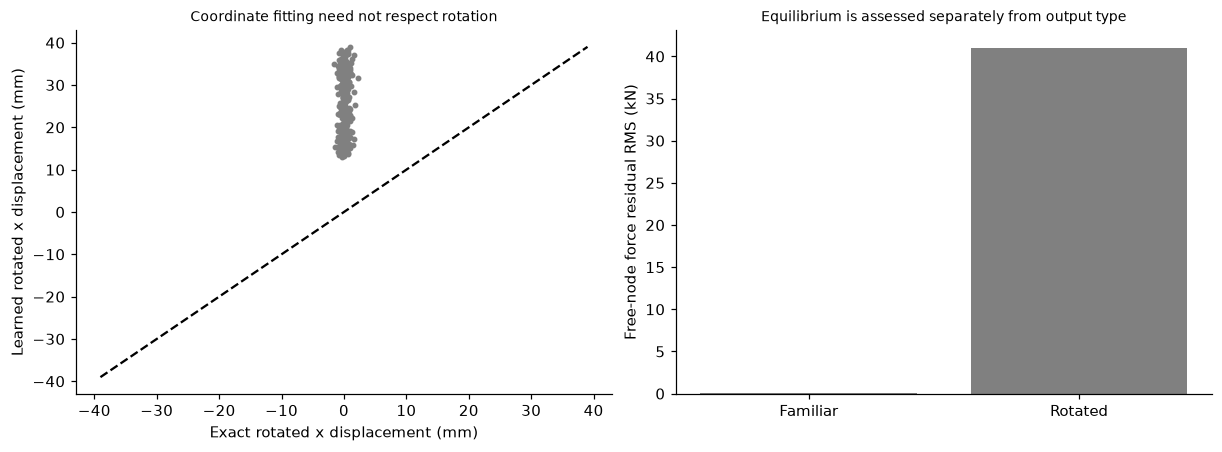

In [2]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures,StandardScaler
from sklearn.linear_model import Ridge
def rotation(theta):return np.array([[np.cos(theta),-np.sin(theta)],[np.sin(theta),np.cos(theta)]])
def features(force,k,theta):return np.c_[force,k,np.cos(theta),np.sin(theta)]
def solve(force,k,theta):
    matrices=np.array([rotation(t)@np.diag(s)@rotation(t).T for t,s in zip(theta,k)]);return np.linalg.solve(matrices,force[...,None])[...,0],matrices
def cohort(n):
    f=rng.normal(size=(n,2));k=rng.uniform(1,3,(n,2));t=rng.uniform(-.25,.25,n);u,K=solve(f,k,t);return f,k,t,u,K
fs,ks,ts,us,_=cohort(1200);model=make_pipeline(StandardScaler(),PolynomialFeatures(2,include_bias=False),Ridge(alpha=1.)).fit(features(fs,ks,ts),us+rng.normal(scale=.01,size=us.shape));f,k,t,u,K=cohort(300);pred=model.predict(features(f,k,t));rot=rotation(np.pi/2);rf=f@rot.T;rt=t+np.pi/2;ru,rK=solve(rf,k,rt);rpred=model.predict(features(rf,k,rt));assert np.allclose(ru,u@rot.T,atol=1e-12);assert np.linalg.eigvalsh(K).min()>0;covariance_error=float(np.sqrt(np.mean((rpred-pred@rot.T)**2)));scores={'Familiar':{'RMSE_mm':float(np.sqrt(np.mean((pred-u)**2))),'force_residual_RMS_kN':float(np.sqrt(np.mean((np.einsum('bij,bj->bi',K,pred)-f)**2)))},'Rotated':{'RMSE_mm':float(np.sqrt(np.mean((rpred-ru)**2))),'force_residual_RMS_kN':float(np.sqrt(np.mean((np.einsum('bij,bj->bi',rK,rpred)-rf)**2)))}};RESULTS.update(source_elements=1200,final_elements=300,geometry_scores=scores,learned_rotation_covariance_RMSE_mm=covariance_error,exact_solver_rotation_covariance=True,coordinate_model_not_equivariant=True);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].scatter(ru[:,0],rpred[:,0],s=8,color='.5');bound=max(abs(ru[:,0]).max(),abs(rpred[:,0]).max());axes[0].plot([-bound,bound],[-bound,bound],color='black',linestyle='--');axes[0].set(xlabel='Exact rotated x displacement (mm)',ylabel='Learned rotated x displacement (mm)',title='Coordinate fitting need not respect rotation');axes[1].bar(range(2),[scores[k]['force_residual_RMS_kN'] for k in scores],color='.5');axes[1].set(xticks=range(2),xticklabels=list(scores),ylabel='Free-node force residual RMS (kN)',title='Equilibrium is assessed separately from output type');plt.show()


## Align each stress with a check that can observe it
 Build a physical stress board for the first fixed final element. A noise-perturbed force prediction is checked both against its measured force and the separately known simulator true force. Missing force is rejected before inference. Rotated inputs use their rotated current stiffness. A changed support clamps free-node x displacement, requiring a different constrained solve; the old predictor lacks that metadata. A counterexample field is all zeros: it passes the fixed-support condition and nonnegative strain energy yet has nonzero force imbalance. An equilibrium-consistent free-tip solution can instead violate the changed x clamp. Report support residual, free-equation residual, displacement error and strain energy separately. These are finite fixtures with explicit tolerances, not a complete structural acceptance standard.


,fixture,support_residual_mm,free_equation_residual_kN,displacement_error_mm,strain_energy_kN_mm
0,Familiar learned,0.000000,0.073748,0.041461,0.091744
1,Noisy measured force,0.000000,0.085937,0.054179,0.103445
2,Noisy true force audit,0.000000,0.180930,0.169081,0.103445
3,Rotated learned,0.000000,31.663702,18.242143,278.229220
4,Zero displacement,0.000000,0.494205,0.285385,0.000000
5,Changed support old solve,0.123727,0.000000,0.123971,0.070073
6,Changed support correct,0.000000,0.000000,0.000000,0.061812


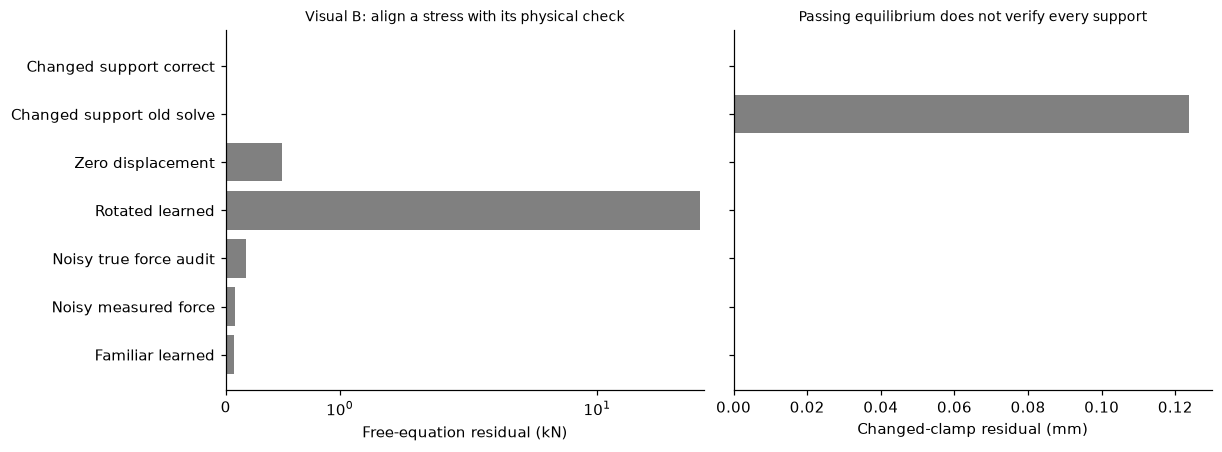

In [3]:
f0=f[0];K0=K[0];u0=u[0];p0=pred[0];noisy_f=f0+np.array([.2,-.1]);noisy_pred=model.predict(features(noisy_f[None],k[:1],t[:1]))[0];changed_u=np.array([0.,f0[1]/K0[1,1]]);rows=[]
def audit(name,displacement,force,matrix,truth,clamp=False):
    residual=matrix@displacement-force;ids=[1] if clamp else [0,1];return {'fixture':name,'support_residual_mm':abs(float(displacement[0])) if clamp else 0.,'free_equation_residual_kN':float(np.linalg.norm(residual[ids])),'displacement_error_mm':float(np.linalg.norm(displacement-truth)),'strain_energy_kN_mm':float(.5*displacement@matrix@displacement)}
rows.append(audit('Familiar learned',p0,f0,K0,u0));rows.append(audit('Noisy measured force',noisy_pred,noisy_f,K0,np.linalg.solve(K0,noisy_f)));rows.append(audit('Noisy true force audit',noisy_pred,f0,K0,u0));rows.append(audit('Rotated learned',rpred[0],rf[0],rK[0],ru[0]));rows.append(audit('Zero displacement',np.zeros(2),f0,K0,u0));rows.append(audit('Changed support old solve',u0,f0,K0,changed_u,True));rows.append(audit('Changed support correct',changed_u,f0,K0,changed_u,True));assert rows[4]['support_residual_mm']==0 and rows[4]['strain_energy_kN_mm']==0 and rows[4]['free_equation_residual_kN']>0;assert rows[-1]['support_residual_mm']==0 and rows[-1]['free_equation_residual_kN']<1e-12;assert rows[-2]['free_equation_residual_kN']<1e-12 and rows[-2]['support_residual_mm']>0;missing=features(f[:1],k[:1],t[:1]);missing[0,0]=np.nan;missing_rejected=not np.isfinite(missing).all();assert missing_rejected;assert np.allclose(np.linalg.solve(K0,2*f0),2*u0);RESULTS.update(physical_stress_board=rows,missing_force_rejected=missing_rejected,energy_nonnegative_does_not_ensure_equilibrium=True,solver_force_scaling_checked=True);display(pd.DataFrame(rows));fig,axes=plt.subplots(1,2,figsize=(11,4));xx=np.arange(len(rows));axes[0].barh(xx,[r['free_equation_residual_kN'] for r in rows],color='.5');axes[0].set(yticks=xx,yticklabels=[r['fixture'] for r in rows],xlabel='Free-equation residual (kN)',xscale='symlog',title='Visual B: align a stress with its physical check');axes[1].barh(xx,[r['support_residual_mm'] for r in rows],color='.5');axes[1].set(yticks=xx,yticklabels=[],xlabel='Changed-clamp residual (mm)',title='Passing equilibrium does not verify every support');plt.show()


In [4]:
summary={'example_id':'code_209','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual source-fitted anisotropic vector response and mechanical comparator', 'rotated geometry force covariance boundary and equilibrium checks', 'explicit corruption and support-change stress-test board', 'separate displacement error force residual energy and field constraints'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual source-fitted anisotropic vector response and mechanical comparator", "rotated geometry force covariance boundary and equilibrium checks", "explicit corruption and support-change stress-test board", "separate displacement error force residual energy and field constraints"], "elapsed_seconds": 0.465, "example_id": "code_209", "hardware": "Darwin arm64 CPU", "results": {"coordinate_model_not_equivariant": true, "energy_nonnegative_does_not_ensure_equilibrium": true, "exact_solver_rotation_covariance": true, "final_elements": 300, "geometry_scores": {"Familiar": {"RMSE_mm": 0.06176607086112501, "force_residual_RMS_kN": 0.1191045310126586}, "Rotated": {"RMSE_mm": 19.820527132017833, "force_residual_RMS_kN": 41.03851916754654}}, "learned_rotation_covariance_RMSE_mm": 19.815292349885553, "missing_force_rejected": true, "physical_stress_board": [{"displacement_error_mm": 0.04146112621102369, "fixture": "Familiar learned", "free_equatio